# Experiment 1 — YesNo Speech Classification

Mahdi Khafaji - 403131107 - m.khafaji@aut.ac.ir

Train and compare Logistic Regression, SVM, Random Forest, and a PyTorch CNN using Torchaudio's YesNo dataset.

The dataset has 60 recordings, each with eight binary yes/no labels.

All outputs are saved to `MyDrive/Speech_Processing_Project/YesNo/`.

## 1. Install/import packages and connect Google Drive
Run this notebook from top to bottom. In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU).

In [1]:
!pip -q install scikit-learn pandas matplotlib seaborn

import os, re, json, random, warnings, subprocess, sys, glob, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.multioutput import MultiOutputClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, multilabel_confusion_matrix,
    confusion_matrix
)

from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('TorchAudio:', torchaudio.__version__)
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

PROJECT_DIR = Path('/content/drive/MyDrive/Speech_Processing_Project')
YESNO_DIR = PROJECT_DIR / 'YesNo'
VOICES_DIR = PROJECT_DIR / 'VOICES'
REPORT_DIR = PROJECT_DIR / 'Reports'
for p in [YESNO_DIR, YESNO_DIR/'models', YESNO_DIR/'figures', YESNO_DIR/'metrics',
          VOICES_DIR, VOICES_DIR/'models', VOICES_DIR/'event_detection',
          VOICES_DIR/'vad', REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print('Results directory:', PROJECT_DIR)

Mounted at /content/drive
PyTorch: 2.14.1+cu130
TorchAudio: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Results directory: /content/drive/MyDrive/Speech_Processing_Project


## 2. Experiment 1 — Load the Torchaudio YesNo dataset

Each item is `(waveform, sample_rate, labels)`. The target is an eight-position sequence, not one class for the entire recording.

In [3]:
from pathlib import Path
import os

# Create the required directories
YESNO_DIR = Path('/content/drive/MyDrive/Speech_Processing_Project/YesNo')

RAW_DIR = YESNO_DIR / 'raw'
MODELS_DIR = YESNO_DIR / 'models'
FIGURES_DIR = YESNO_DIR / 'figures'
METRICS_DIR = YESNO_DIR / 'metrics'

for folder in [RAW_DIR, MODELS_DIR, FIGURES_DIR, METRICS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Directories created successfully!")
print("Dataset directory:", RAW_DIR)

Directories created successfully!
Dataset directory: /content/drive/MyDrive/Speech_Processing_Project/YesNo/raw


In [4]:
yesno_dataset = torchaudio.datasets.YESNO(
    root=str(YESNO_DIR / 'raw'),
    download=True
)
print('Number of recordings:', len(yesno_dataset))
waveform, sample_rate, labels = yesno_dataset[0]
print('Waveform shape:', tuple(waveform.shape))
print('Sample rate:', sample_rate)
print('Eight binary labels:', labels)

100%|██████████| 4.49M/4.49M [00:03<00:00, 1.38MB/s]


Number of recordings: 60
Waveform shape: (1, 50800)
Sample rate: 8000
Eight binary labels: [0, 0, 0, 0, 1, 1, 1, 1]


## 3. Extract MFCC statistics for traditional classifiers

For each recording, calculate MFCCs and concatenate the mean and standard deviation of each coefficient. This creates a fixed-length feature vector.

In [5]:
TARGET_SR = 8000
N_MFCC = 20

mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=TARGET_SR,
    n_mfcc=N_MFCC,
    melkwargs={'n_fft': 400, 'hop_length': 160, 'n_mels': 40}
)

X_features, y_labels, yesno_waveforms = [], [], []
for i in range(len(yesno_dataset)):
    wav, sr, lab = yesno_dataset[i]
    wav = wav.mean(dim=0, keepdim=True)
    if sr != TARGET_SR:
        wav = torchaudio.functional.resample(wav, sr, TARGET_SR)
    mfcc = mfcc_transform(wav).squeeze(0)
    feat = torch.cat([mfcc.mean(dim=1), mfcc.std(dim=1)]).numpy()
    X_features.append(feat)
    y_labels.append(np.asarray(lab, dtype=np.int64))
    yesno_waveforms.append(wav.squeeze(0).numpy())

X_features = np.asarray(X_features, dtype=np.float32)
y_yesno = np.asarray(y_labels, dtype=np.int64)
print('Feature matrix:', X_features.shape)
print('Target matrix:', y_yesno.shape)
print('Label values:', np.unique(y_yesno))

Feature matrix: (60, 40)
Target matrix: (60, 8)
Label values: [0 1]


## 4. Train/test split and traditional classifiers

We use an 80/20 split. Because the dataset is small, results should be interpreted as a small educational benchmark rather than a definitive performance estimate.

In [6]:
indices = np.arange(len(y_yesno))
train_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=SEED, shuffle=True
)
X_train, X_test = X_features[train_idx], X_features[test_idx]
y_train, y_test = y_yesno[train_idx], y_yesno[test_idx]

traditional_models = {
    'Logistic Regression': MultiOutputClassifier(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))
    ),
    'SVM (RBF)': MultiOutputClassifier(
        make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced'))
    ),
    'Random Forest': MultiOutputClassifier(
        RandomForestClassifier(n_estimators=300, random_state=SEED, class_weight='balanced')
    )
}

yesno_results = []
yesno_predictions = {}
for name, model in traditional_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    yesno_predictions[name] = pred
    row = {
        'Model': name,
        'Exact Match Accuracy': accuracy_score(y_test, pred),
        'Hamming Accuracy': 1.0 - np.mean(y_test != pred),
        'Micro F1': f1_score(y_test, pred, average='micro', zero_division=0),
        'Macro F1': f1_score(y_test, pred, average='macro', zero_division=0),
        'Micro Precision': precision_score(y_test, pred, average='micro', zero_division=0),
        'Micro Recall': recall_score(y_test, pred, average='micro', zero_division=0)
    }
    yesno_results.append(row)
    import joblib
    joblib.dump(model, YESNO_DIR/'models'/f'{name.lower().replace(" ", "_").replace("(", "").replace(")", "")}.joblib')

yesno_classic_df = pd.DataFrame(yesno_results)
display(yesno_classic_df.round(4))
yesno_classic_df.to_csv(YESNO_DIR/'metrics'/'traditional_models_metrics.csv', index=False)

,Model,Exact Match Accuracy,Hamming Accuracy,Micro F1,Macro F1,Micro Precision,Micro Recall
0,Logistic Regression,0.0,0.5208,0.5577,0.5440,0.5686,0.5472
1,SVM (RBF),0.0,0.5521,0.5905,0.5849,0.5962,0.5849
2,Random Forest,0.0,0.5729,0.6239,0.6190,0.6071,0.6415


## 5. PyTorch CNN for YesNo sequence classification

The CNN receives a log-Mel spectrogram and predicts eight binary outputs. The loss is binary cross-entropy with logits.

CNN input tensor: (60, 64, 401)
Epoch 05/35 | train=0.6897 | test=0.7055
Epoch 10/35 | train=0.6751 | test=0.7129
Epoch 15/35 | train=0.6552 | test=0.7099
Epoch 20/35 | train=0.6126 | test=0.6841
Epoch 25/35 | train=0.5701 | test=0.6308
Epoch 30/35 | train=0.5339 | test=0.5642
Epoch 35/35 | train=0.4736 | test=0.5474


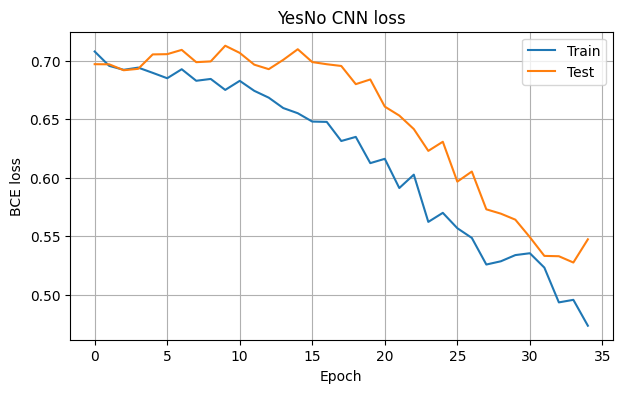

In [7]:
MAX_SECONDS = 8
MAX_SAMPLES = TARGET_SR * MAX_SECONDS
N_MELS = 64

mel_transform_yesno = torchaudio.transforms.MelSpectrogram(
    sample_rate=TARGET_SR, n_fft=400, hop_length=160, n_mels=N_MELS
)

def waveform_to_logmel(wav):
    wav = torch.tensor(wav, dtype=torch.float32).flatten()
    if len(wav) < MAX_SAMPLES:
        wav = F.pad(wav, (0, MAX_SAMPLES-len(wav)))
    else:
        wav = wav[:MAX_SAMPLES]
    mel = mel_transform_yesno(wav.unsqueeze(0)).squeeze(0)
    return torch.log(mel + 1e-6)

X_mel = torch.stack([waveform_to_logmel(w) for w in yesno_waveforms])
print('CNN input tensor:', tuple(X_mel.shape))

class YesNoTorchDataset(Dataset):
    def __init__(self, ids):
        self.ids = ids
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        j = self.ids[i]
        return X_mel[j].unsqueeze(0), torch.tensor(y_yesno[j], dtype=torch.float32)

train_loader = DataLoader(YesNoTorchDataset(train_idx), batch_size=8, shuffle=True)
test_loader = DataLoader(YesNoTorchDataset(test_idx), batch_size=8, shuffle=False)

class YesNoCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten()
        )
        self.classifier = nn.Sequential(nn.Linear(64*4*4, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 8))
    def forward(self, x):
        return self.classifier(self.features(x))

cnn_yesno = YesNoCNN().to(DEVICE)
optimizer = torch.optim.Adam(cnn_yesno.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.BCEWithLogitsLoss()
EPOCHS_YESNO = 35
history_yesno = {'train_loss': [], 'test_loss': []}

for epoch in range(EPOCHS_YESNO):
    cnn_yesno.train()
    running = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = cnn_yesno(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb)
    train_loss = running / len(train_idx)

    cnn_yesno.eval()
    val_running = 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            val_running += criterion(cnn_yesno(xb), yb).item() * len(xb)
    test_loss = val_running / len(test_idx)
    history_yesno['train_loss'].append(train_loss)
    history_yesno['test_loss'].append(test_loss)
    if (epoch+1) % 5 == 0:
        print(f'Epoch {epoch+1:02d}/{EPOCHS_YESNO} | train={train_loss:.4f} | test={test_loss:.4f}')

plt.figure(figsize=(7,4))
plt.plot(history_yesno['train_loss'], label='Train')
plt.plot(history_yesno['test_loss'], label='Test')
plt.xlabel('Epoch'); plt.ylabel('BCE loss'); plt.title('YesNo CNN loss')
plt.legend(); plt.grid(True)
plt.savefig(YESNO_DIR/'figures'/'cnn_loss.png', dpi=160, bbox_inches='tight')
plt.show()

torch.save(cnn_yesno.state_dict(), YESNO_DIR/'models'/'yesno_cnn.pth')

## 6. Evaluate all YesNo models

- **Exact Match Accuracy:** all eight positions must be correct for a recording.
- **Hamming Accuracy:** proportion of individual yes/no positions predicted correctly.
- **Micro/Macro F1:** aggregate binary classification performance across the eight positions.

,Model,Exact Match Accuracy,Hamming Accuracy,Micro F1,Macro F1,Micro Precision,Micro Recall
0,Logistic Regression,0.0000,0.5208,0.5577,0.5440,0.5686,0.5472
1,SVM (RBF),0.0000,0.5521,0.5905,0.5849,0.5962,0.5849
2,Random Forest,0.0000,0.5729,0.6239,0.6190,0.6071,0.6415
3,PyTorch CNN,0.0833,0.7396,0.7423,0.7082,0.8182,0.6792


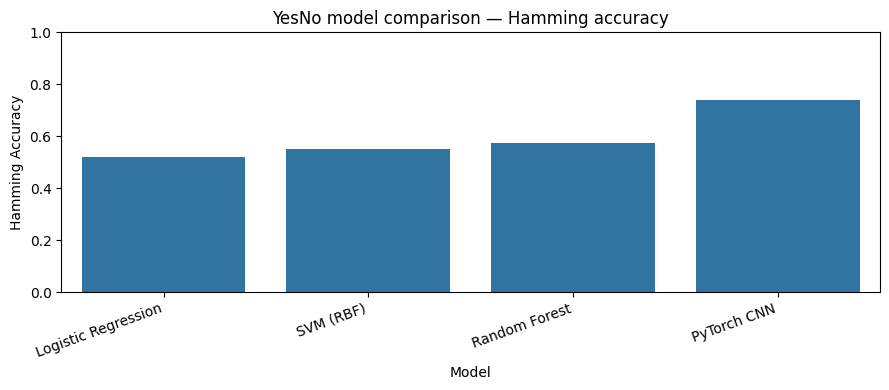

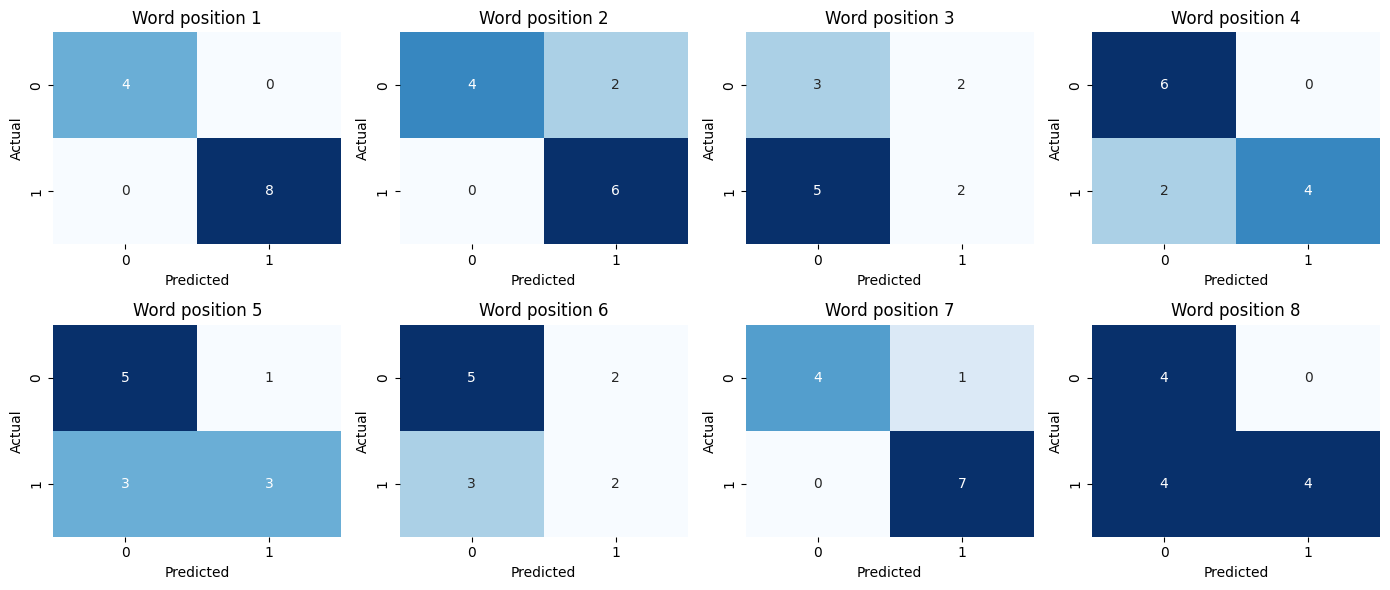

In [8]:
cnn_yesno.eval()
cnn_preds, cnn_true = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs = torch.sigmoid(cnn_yesno(xb.to(DEVICE))).cpu().numpy()
        cnn_preds.append((probs >= 0.5).astype(int))
        cnn_true.append(yb.numpy().astype(int))
cnn_pred = np.vstack(cnn_preds)
cnn_true = np.vstack(cnn_true)

cnn_metrics = {
    'Model': 'PyTorch CNN',
    'Exact Match Accuracy': accuracy_score(cnn_true, cnn_pred),
    'Hamming Accuracy': 1.0 - np.mean(cnn_true != cnn_pred),
    'Micro F1': f1_score(cnn_true, cnn_pred, average='micro', zero_division=0),
    'Macro F1': f1_score(cnn_true, cnn_pred, average='macro', zero_division=0),
    'Micro Precision': precision_score(cnn_true, cnn_pred, average='micro', zero_division=0),
    'Micro Recall': recall_score(cnn_true, cnn_pred, average='micro', zero_division=0)
}
all_yesno_results = pd.concat([yesno_classic_df, pd.DataFrame([cnn_metrics])], ignore_index=True)
display(all_yesno_results.round(4))
all_yesno_results.to_csv(YESNO_DIR/'metrics'/'all_models_metrics.csv', index=False)

plt.figure(figsize=(9,4))
sns.barplot(data=all_yesno_results, x='Model', y='Hamming Accuracy')
plt.xticks(rotation=20, ha='right'); plt.ylim(0,1)
plt.title('YesNo model comparison — Hamming accuracy')
plt.tight_layout()
plt.savefig(YESNO_DIR/'figures'/'model_comparison.png', dpi=160)
plt.show()

# Per-position CNN confusion matrices
fig, axes = plt.subplots(2, 4, figsize=(14,6))
for k, ax in enumerate(axes.flat):
    cm = confusion_matrix(cnn_true[:,k], cnn_pred[:,k], labels=[0,1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f'Word position {k+1}')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig(YESNO_DIR/'figures'/'cnn_position_confusion_matrices.png', dpi=160)
plt.show()